# Flower Classification with a Single Neuron + One-Hot Sentence Vectors
**Roll No:** G25AIT2032

**Part 1** – A single sigmoid neuron (2 inputs → 1 output) trained with stochastic gradient descent to classify flowers as *blue (0)* or *red (1)* from petal length and width.
**Part 2** – One-hot / bag-of-words sentence vectors and a linear layer (`S = h · W`).

## Part 1 – Single-neuron flower classifier

In [15]:
%matplotlib inline
import time
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

SEED = 2032                      # fixed seed -> reproducible results
np.random.seed(SEED)

In [16]:
# each point is [length, width, type]  (type: 0 = blue, 1 = red)
data = [[3,   1.5, 1],
        [2,   1,   0],
        [4,   1.5, 1],
        [3,   1,   0],
        [3.5, .5,  1],
        [2,   .5,  0],
        [5.5, 1,   1],
        [1,   1,   0]]

# Change these values to see which class a new flower belongs to (in-class activity)
# mystery_flower = [4.5, 1]
# mystery_flower = [1.5, 0.8]
mystery_flower = [5, 1.5]

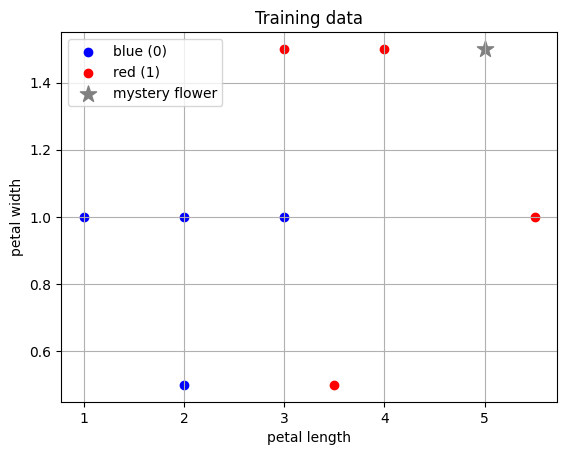

In [17]:
def vis_data():
    plt.grid(True)
    for length, width, kind in data:
        plt.scatter(length, width, c='r' if kind == 1 else 'b')
    plt.scatter(*mystery_flower, c='gray', marker='*', s=150)
    plt.xlabel("petal length"); plt.ylabel("petal width")
    # legend using proxy handles
    plt.scatter([], [], c='b', label='blue (0)')
    plt.scatter([], [], c='r', label='red (1)')
    plt.scatter([], [], c='gray', marker='*', s=150, label='mystery flower')
    plt.legend(loc='upper left')

vis_data()
plt.title("Training data")
plt.show()

**Network**

```
      o   flower type
     / \   w1, w2, b
    o   o  length, width
```

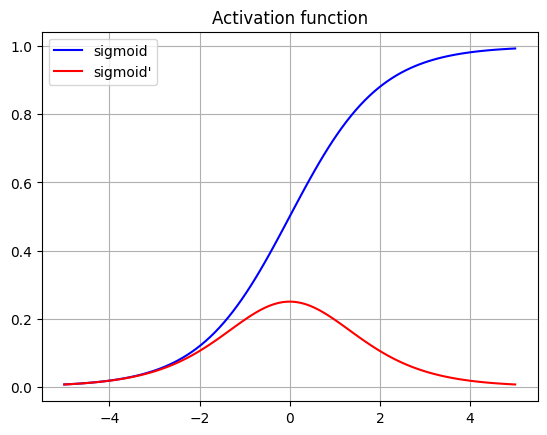

In [18]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_p(x):
    s = sigmoid(x)
    return s * (1 - s)

X = np.linspace(-5, 5, 100)
plt.plot(X, sigmoid(X),   c="b", label="sigmoid")
plt.plot(X, sigmoid_p(X), c="r", label="sigmoid'")
plt.grid(True); plt.legend(); plt.title("Activation function")
plt.show()

### Training function
One function now serves both the normal run and the *iterations / learning-rate* experiment.

> **Why some waveforms were missing earlier:** the cost was logged only when `i % 100 == 0`.
> With `iterations = 100` that happens exactly **once** (`i = 0`), so `plt.plot` received a single point and drew nothing.
> Now the log interval scales with the run (`log_every = max(1, iterations // 100)`), so every run gives ~100 points and a visible curve.

In [19]:
def total_cost(w1, w2, b):
    """Sum of squared errors over ALL data points."""
    return sum((sigmoid(w1 * p[0] + w2 * p[1] + b) - p[2]) ** 2 for p in data)

def train(iterations=10000, learning_rate=0.1, seed=SEED):
    rng = np.random.RandomState(seed)          # same start weights for fair comparison
    w1, w2, b = rng.randn(), rng.randn(), rng.randn()

    log_every = max(1, iterations // 100)      # ~100 points on every curve
    steps, costs = [], []

    for i in range(iterations):
        point = data[rng.randint(len(data))]   # random point (SGD)
        z    = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z)
        target = point[2]

        if i % log_every == 0:
            steps.append(i)
            costs.append(total_cost(w1, w2, b))

        dcost_dz = 2 * (pred - target) * sigmoid_p(z)   # chain rule
        w1 -= learning_rate * dcost_dz * point[0]
        w2 -= learning_rate * dcost_dz * point[1]
        b  -= learning_rate * dcost_dz

    steps.append(iterations); costs.append(total_cost(w1, w2, b))
    return steps, costs, w1, w2, b

### Baseline run (10 000 iterations, lr = 0.1)

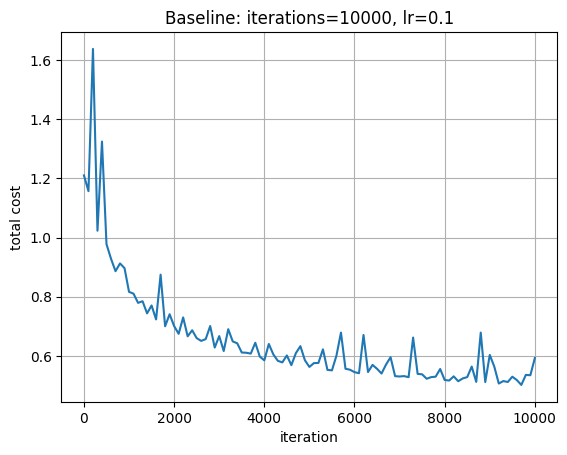

w1=2.788  w2=0.933  b=-8.390  final cost=0.5929


In [20]:
steps, costs, w1, w2, b = train(10000, 0.1)
plt.plot(steps, costs)
plt.xlabel("iteration"); plt.ylabel("total cost"); plt.title("Baseline: iterations=10000, lr=0.1")
plt.grid(True); plt.show()
print(f"w1={w1:.3f}  w2={w2:.3f}  b={b:.3f}  final cost={costs[-1]:.4f}")

### In-class activity – changing iterations and learning rate

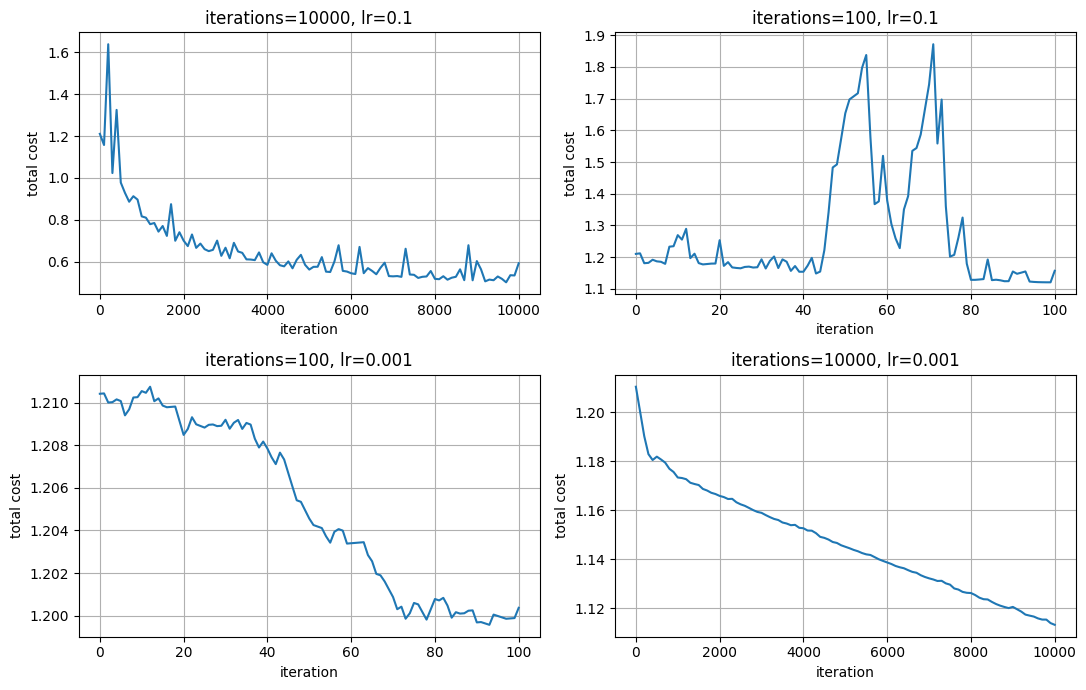

,iterations,learning_rate,start cost,final cost,time (s)
0,10000,0.100,1.2104,0.5929,0.08
1,100,0.100,1.2104,1.1571,0.00
2,100,0.001,1.2104,1.2004,0.00
3,10000,0.001,1.2104,1.1133,0.08


In [21]:
itlr = [(10000, 0.1), (100, 0.1), (100, 0.001), (10000, 0.001)]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
rows = []
for ax, (it, lr) in zip(axes.ravel(), itlr):
    t0 = time.time()
    s, c, _w1, _w2, _b = train(it, lr)        # separate variables: baseline weights stay untouched
    elapsed = time.time() - t0
    ax.plot(s, c, marker='o' if len(s) < 30 else None)
    ax.set_title(f"iterations={it}, lr={lr}")
    ax.set_xlabel("iteration"); ax.set_ylabel("total cost"); ax.grid(True)
    rows.append({"iterations": it, "learning_rate": lr,
                 "start cost": round(c[0], 4), "final cost": round(c[-1], 4),
                 "time (s)": round(elapsed, 2)})
fig.tight_layout(); plt.show()
pd.DataFrame(rows)

**Observation**
- `lr=0.1` learns fast but the curve is noisy (single-point SGD updates); `lr=0.001` is smooth but barely moves in 100 steps and is still slow at 10 000.
- Very few iterations (100) are not enough to converge, whatever the learning rate.
- Best combination: **10 000 iterations with lr = 0.1**.

### Predict the mystery flower (using the well-trained baseline model)

In [22]:
z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)
print(f"prediction = {pred:.4f}  ->", "RED (1)" if pred > .5 else "BLUE (0)")
print("close to 0 -> blue, close to 1 -> red")

prediction = 0.9990  -> RED (1)
close to 0 -> blue, close to 1 -> red


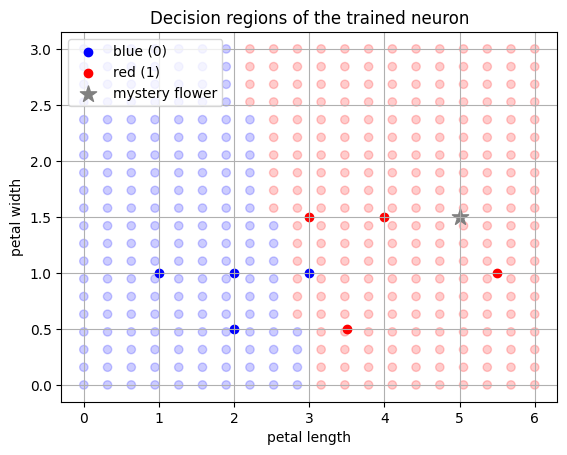

In [23]:
# network predictions over the length-width plane
xs, ys = np.meshgrid(np.linspace(0, 6, 20), np.linspace(0, 3, 20))
preds = sigmoid(w1 * xs + w2 * ys + b)
plt.scatter(xs.ravel(), ys.ravel(), c=np.where(preds > .5, "r", "b").ravel(), alpha=.2)
vis_data()
plt.title("Decision regions of the trained neuron")
plt.show()

## Part 2 – One-hot sentence vectors (in-class activity)

Each sentence becomes a vector over the vocabulary (1 = word present, 0 = absent).
Stacking the vectors gives the matrix `h`, and a linear layer computes `S = h · W`.

In [24]:
# ---- new sentences & vocabulary (4 sentences, 6 words) ----
sentences = [
    "Krishna River Bridge",
    "Godavari River Barrage",
    "Krishna Delta Barrage",
    "Godavari Delta Bridge",
]

# build vocabulary automatically (first-seen order)
V = []
for s in sentences:
    for w in s.split():
        if w not in V:
            V.append(w)

print("Vocabulary:", V, "| size =", len(V))

def sentence_vector(sentence):
    words = sentence.split()
    return [1 if w in words else 0 for w in V]

vectors = [sentence_vector(s) for s in sentences]
for i, (s, v) in enumerate(zip(sentences, vectors), 1):
    print(f"S{i}: {v}   <- '{s}'")

Vocabulary: ['Krishna', 'River', 'Bridge', 'Godavari', 'Barrage', 'Delta'] | size = 6
S1: [1, 1, 1, 0, 0, 0]   <- 'Krishna River Bridge'
S2: [0, 1, 0, 1, 1, 0]   <- 'Godavari River Barrage'
S3: [1, 0, 0, 0, 1, 1]   <- 'Krishna Delta Barrage'
S4: [0, 0, 1, 1, 0, 1]   <- 'Godavari Delta Bridge'


,Krishna,River,Bridge,Godavari,Barrage,Delta
S1,1,1,1,0,0,0
S2,0,1,0,1,1,0
S3,1,0,0,0,1,1
S4,0,0,1,1,0,1


h shape: (4, 6)


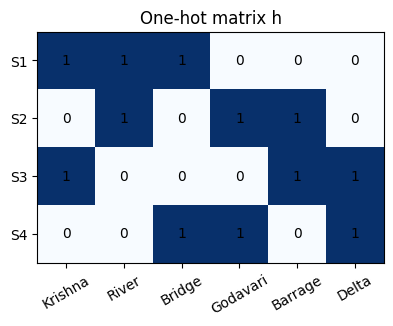

In [25]:
# Layer 1 - lookup matrix h  (sentences x vocabulary)
h = np.array(vectors)
labels = [f"S{i+1}" for i in range(len(sentences))]
display(pd.DataFrame(h, index=labels, columns=V))
print("h shape:", h.shape)          # (4, 6)

fig, ax = plt.subplots(figsize=(6, 3))
ax.imshow(h, cmap="Blues")
ax.set_xticks(range(len(V)), V, rotation=30); ax.set_yticks(range(len(labels)), labels)
for r in range(h.shape[0]):
    for c in range(h.shape[1]):
        ax.text(c, r, h[r, c], ha="center", va="center")
ax.set_title("One-hot matrix h"); plt.show()

In [26]:
# Layer 2 - S = h . W   (h: 4x6, W: 6x2  ->  S: 4x2)
rng = np.random.RandomState(SEED)
W = rng.randn(len(V), 2)           # vocabulary -> 2 output neurons
S = np.dot(h, W)

print("W shape:", W.shape)
display(pd.DataFrame(W, index=V, columns=["neuron 1", "neuron 2"]).round(3))
print("S shape:", S.shape)
display(pd.DataFrame(S, index=labels, columns=["neuron 1", "neuron 2"]).round(3))

W shape: (6, 2)


,neuron 1,neuron 2
Krishna,0.961,-0.927
River,-1.376,0.479
Bridge,1.141,-0.366
Godavari,-0.179,-0.754
Barrage,0.830,0.457
Delta,-0.999,-0.640


S shape: (4, 2)


,neuron 1,neuron 2
S1,0.727,-0.814
S2,-0.725,0.183
S3,0.792,-1.109
S4,-0.037,-1.759


In [27]:
# Extra: how similar are the sentences? (cosine similarity of the rows of h)
norm = np.linalg.norm(h, axis=1, keepdims=True)
cos = (h @ h.T) / (norm @ norm.T)
display(pd.DataFrame(cos, index=labels, columns=labels).round(2))

,S1,S2,S3,S4
S1,1.00,0.33,0.33,0.33
S2,0.33,1.00,0.33,0.33
S3,0.33,0.33,1.00,0.33
S4,0.33,0.33,0.33,1.00


In [28]:
# Part 2 – One-hot vectors: In class activity-- another example
S1 = "New York Times"
S2 = "Los Angeles Times"
S3 = "Los Angeles York"

V = ['New', 'York', 'Times', 'Los', 'Angeles']   # vocabulary, 5 unique words
print(len(V))

# Sentence vectors (1 = word present, 0 = absent) Applying One hot encoding to the sentences
# S1= [1 1 1 0 0]
# S2= [0 0 1 1 1]
# S3= [0 1 0 1 1]

def sentence_vector(sentence):
    words = sentence.split()
    return [1 if w in words else 0 for w in V]

s1 = sentence_vector(S1)
s2 = sentence_vector(S2)
s3 = sentence_vector(S3)

print("S1:", s1)   # expected [1, 1, 1, 0, 0]
print("S2:", s2)   # expected [0, 0, 1, 1, 1]
print("S3:", s3)   # expected [0, 1, 0, 1, 1]

# Layer 1 – lookup function h (h is a matrix of size 3×5)
# s=h*w

import numpy as np

h = np.array([s1, s2, s3])
print("h matrix")
print (h)
print("h shape:", h.shape)    # (3, 5)

# Layer 2 – S = h · W  (h: 3×5, W: 5×2, output S: 3×2)

W = np.random.randn(5, 2)     # 5 vocabulary words -> 2 output neurons, random values
S = np.dot(h, W)              # use np.dot

print("W shape:", W.shape)    # (5, 2)
print ("w",W)
print("Output matrix: S shape:", S.shape)    # (3, 2)
print(S)


5
S1: [1, 1, 1, 0, 0]
S2: [0, 0, 1, 1, 1]
S3: [0, 1, 0, 1, 1]
h matrix
[[1 1 1 0 0]
 [0 0 1 1 1]
 [0 1 0 1 1]]
h shape: (3, 5)
W shape: (5, 2)
w [[ 0.96098242 -0.92708498]
 [-1.37557638  0.47918581]
 [ 1.1412253  -0.36607652]
 [-0.17903596 -0.75359181]
 [ 0.82963391  0.45728229]]
Output matrix: S shape: (3, 2)
[[ 0.72663134 -0.81397569]
 [ 1.79182325 -0.66238605]
 [-0.72497844  0.18287628]]
